#LAB 1 ALA
by Daria Plys

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

In [ ]:
batman = np.array([[0, 0], [1, 0.2], [0.4, 1], [0.5, 0.4], [0, 0.8], [-0.5, 0.4], [-0.4, 1], [-1, 0.2], [0, 0]])

In [ ]:
lynx = np.array([
[209.70, 368.42], [157.63, 332.16], [118.82, 284.21], [80.95, 224.56], [43.08, 244.44], [20.36, 266.67], [-4.26, 293.57], [2.37, 263.16], [-20.36, 292.40], [-39.29, 299.42], [-21.30, 259.65],
[-50.65, 267.84], [-39.29, 242.11], [-55.38, 240.94], [-100.83, 300.58], [-149.11, 345.03], [-172.78, 361.40], [-189.82, 300.58], [-192.66, 225.73], [-181.30, 145.03], [-168.05, 104.09], [-184.14, 66.67],
[-186.98, 31.58], [-183.20, 3.51], [-208.76, -4.68], [-197.40, -29.24], [-182.25, -44.44], [-203.08, -43.27], [-172.78, -92.40], [-131.12, -126.32], [-101.78, -147.37], [-74.32, -163.74], [-110.30, -224.56],
[-143.43, -287.72], [-161.42, -240.94], [-282.60, -221.05], [-388.64, -205.85], [-370.65, -301.75], [-339.41, -397.66], [18.46, -397.66], [345.09, -400.00], [359.29, -378.95], [367.81, -342.69], [346.98, -
362.57], [363.08, -302.92], [357.40, -243.27], [348.88, -266.67], [336.57, -201.17], [290.18, -135.67], [240.00, -118.13], [258.93, -164.91], [257.99, -228.07], [252.31, -271.35], [256.09, -333.33],
[247.57, -359.06], [230.53, -307.60], [194.56, -238.60], [160.47, -181.29], [120.71, -149.71], [165.21, -132.16], [201.18, -100.58], [183.20, -99.42], [221.07, -73.68], [253.25, -24.56], [222.01, -23.39],
[251.36, -1.17], [262.72, 24.56], [234.32, 25.73], [214.44, 42.11], [202.13, 60.82], [220.12, 101.75], [234.32, 160.23], [240.00, 230.41], [232.43, 316.96]
])

In [ ]:
def read_off(filename: str):
    with open(filename, 'r') as f:
        if 'OFF' != f.readline().strip():
            raise ValueError('Not a valid OFF header')

        n_verts, n_faces, _ = map(int, f.readline().strip().split())

        verts = [list(map(float, f.readline().strip().split())) for _ in range(n_verts)]

        faces = [list(map(int, f.readline().strip().split()[1:])) for _ in range(n_faces)]

    return np.array(verts), faces

In [ ]:
def plot_off(vertices, faces):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')

    mesh = Poly3DCollection([vertices[face] for face in faces],
                            alpha=0.3, edgecolor='k')
    ax.add_collection3d(mesh)

    ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=2, c='r')

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    ax.auto_scale_xyz(vertices[:, 0], vertices[:, 1], vertices[:, 2])

    plt.show()

## Part 1 in 2D

### Task 1

In [ ]:
def stretch(X, a, b):
    X = X.copy()
    M = np.array([[a, 0], [0, b]])
    return M @ X, M

In [ ]:
def shear(X, a, b):
    X = X.copy()
    M = np.array([[1, a], [b, 1]])
    return M @ X, M

In [ ]:
def reflection(X, a, b):
    X = X.copy()
    if a == 0 and b == 0:
      raise ValueError("cannot reflect")
    else:
      M = np.array([[a**2-b**2,2*a*b],[2*a*b,b**2 - a**2]])/(a**2+b**2)
    return M @ X, M

In [ ]:
def rotation(X, angle):
    X = X.copy()
    M = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    return M @ X, M

In [ ]:
def show(image, image_new, M):
    print(M)
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.plot(image[0], image[1])
    plt.title("Original")
    plt.axis("equal")

    plt.subplot(1, 2, 2)
    plt.plot(image_new[0], image_new[1])
    plt.title("Transformed")
    plt.axis("equal")

    plt.show()

stretch
[[1.5 0. ]
 [0.  0.7]]


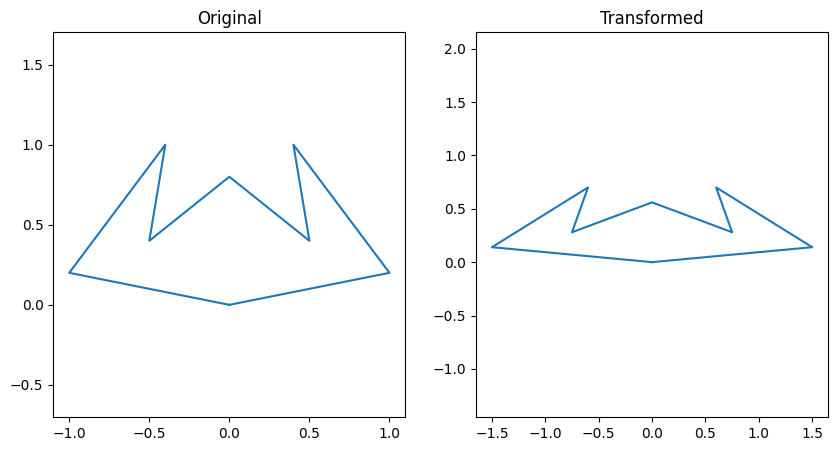

shear
[[1.  0.5]
 [0.  1. ]]


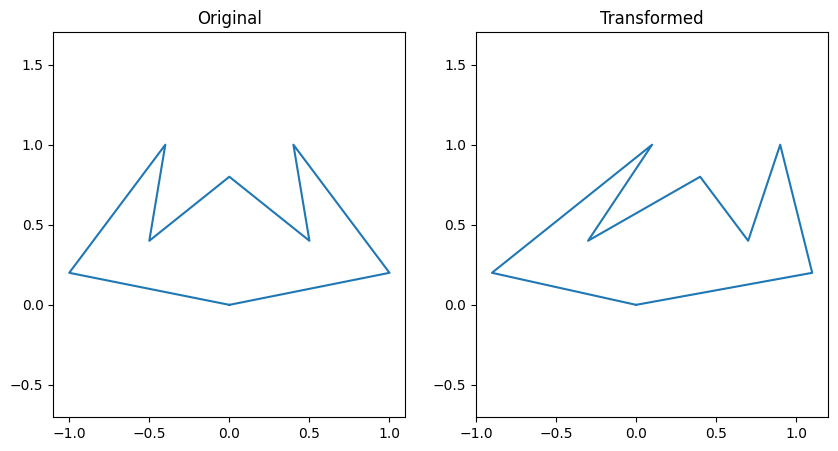

reflection
[[0. 1.]
 [1. 0.]]


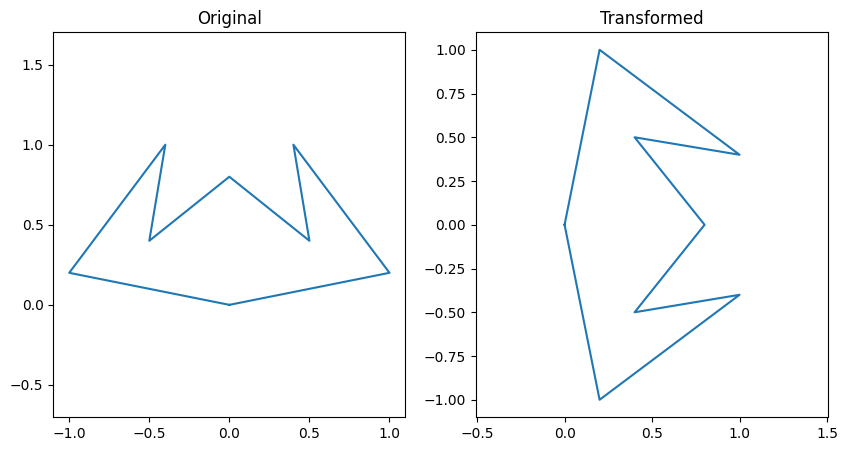

rotation
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


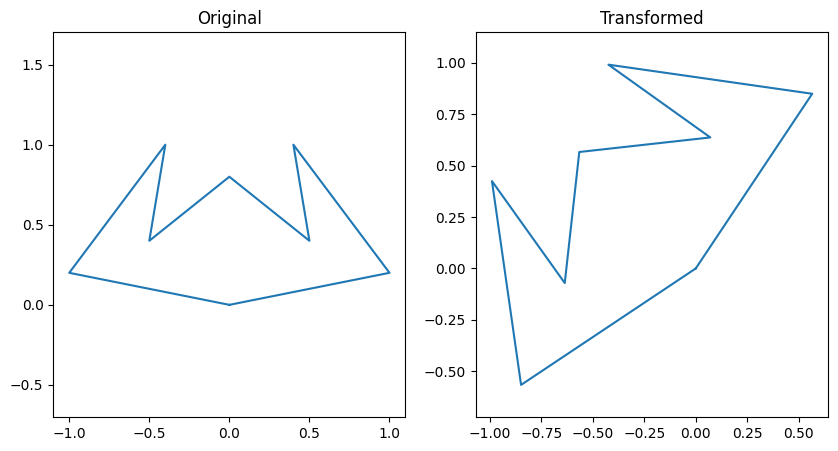

stretch
[[1.5 0. ]
 [0.  0.7]]


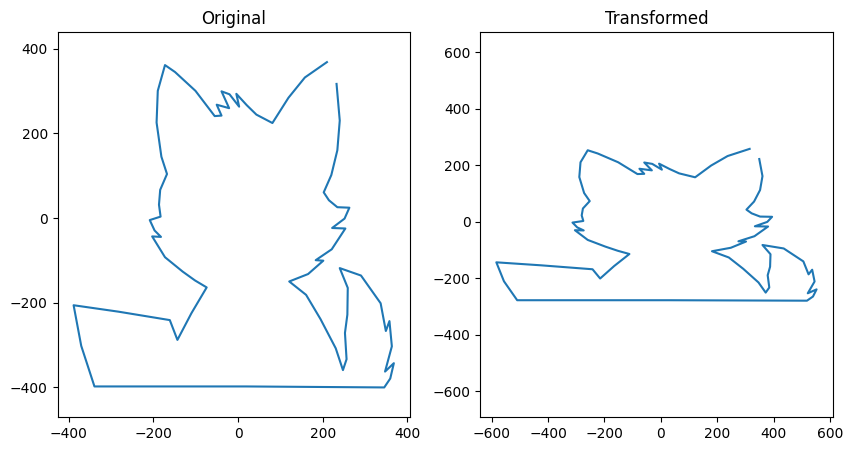

shear
[[1.  0.5]
 [0.  1. ]]


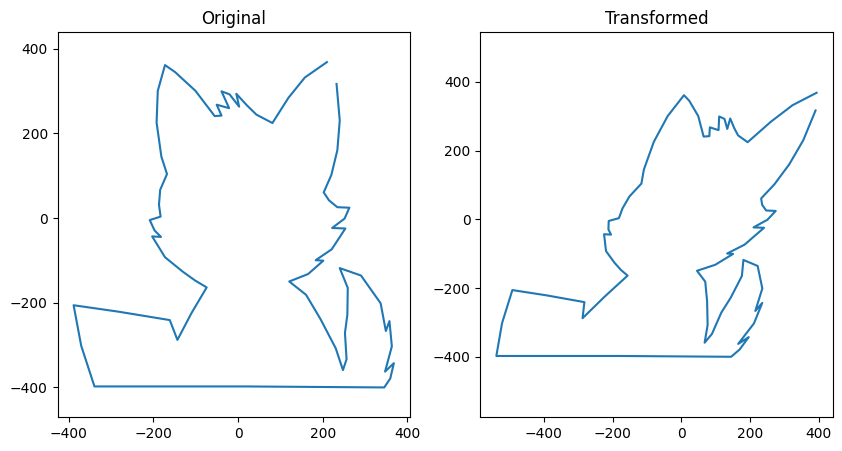

reflection
[[0. 1.]
 [1. 0.]]


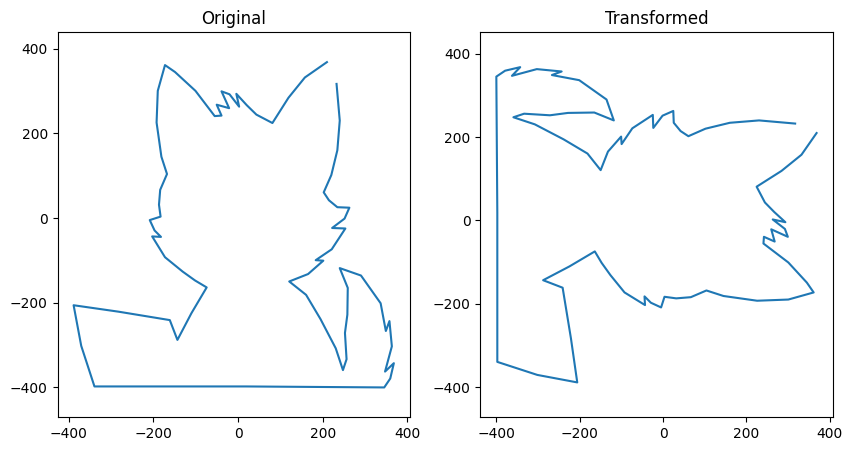

rotation
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


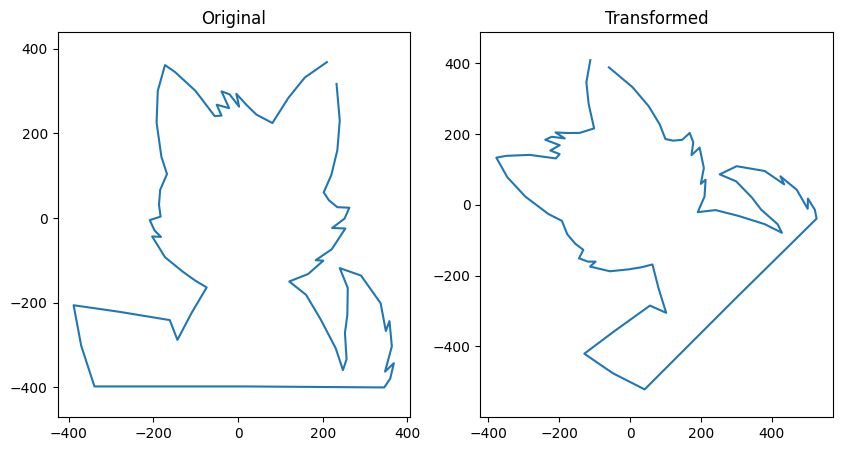

In [ ]:
images = {"Batman": batman.T,
          "Lynx": lynx.T,}

for name, shape in images.items():

    S_new, M = stretch(shape, 1.5, 0.7)
    print('stretch')
    show(shape, S_new, M)

    S_new, M = shear(shape, 0.5, 0)
    print('shear')
    show(shape, S_new, M)

    S_new, M = reflection(shape, 1, 1)
    print('reflection')
    show(shape, S_new, M)

    S_new, M = rotation(shape, np.pi/4)
    print('rotation')
    show(shape, S_new, M)

Я ще хочу більше спробувати опцій, тому тут візьмемо по декілька координат на 1 функцію щоб дослідити резалти

In [ ]:
L = lynx.T

stretch 2 1
[[2 0]
 [0 1]]


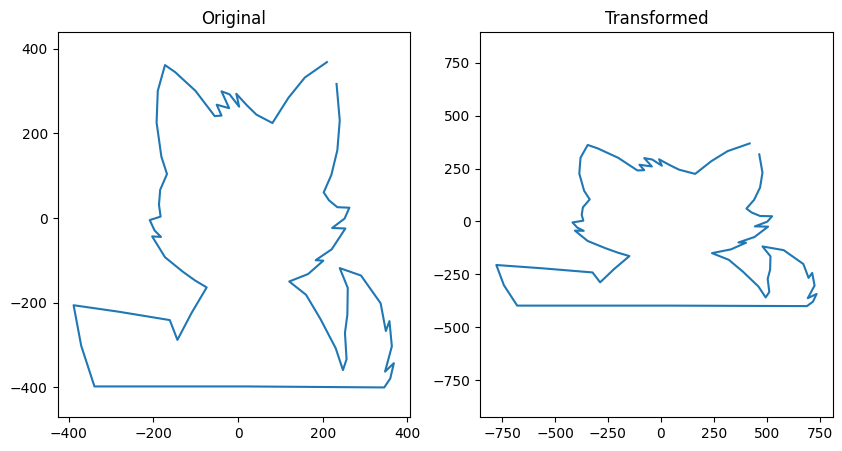

stretch 1 0.5
[[1.  0. ]
 [0.  0.5]]


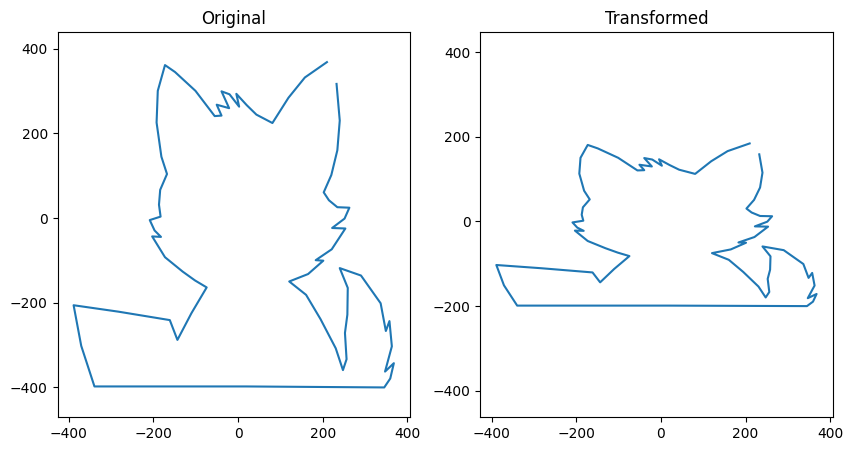

stretch -1 1
[[-1  0]
 [ 0  1]]


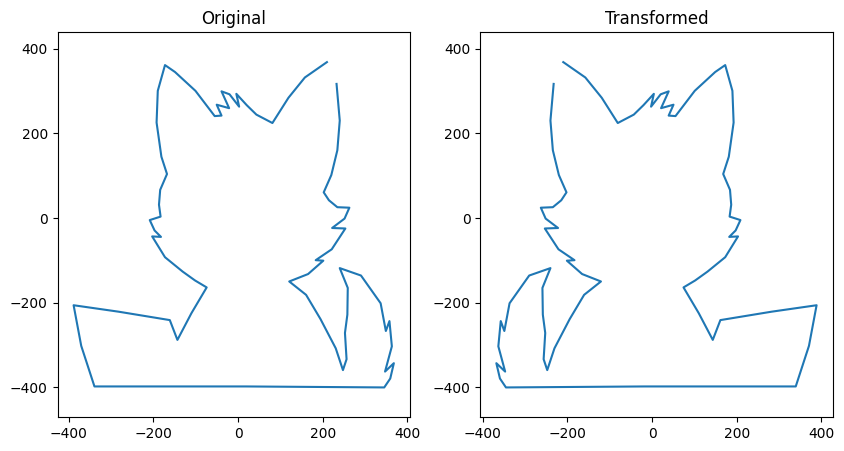

stretch 2 2
[[2 0]
 [0 2]]


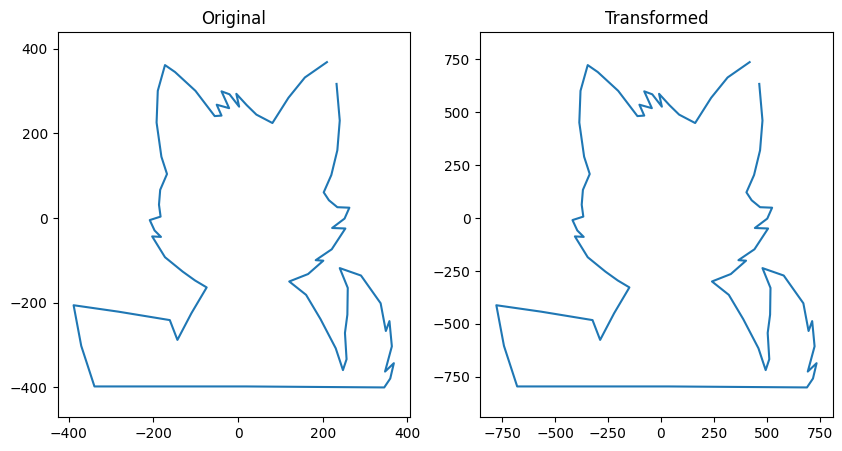

In [ ]:
for a, b in [(2, 1), (1, 0.5), (-1, 1), (2, 2)]:
    print("stretch", a, b)
    L_new, M = stretch(L, a, b)
    show(L, L_new, M)

shear 0.5 0
[[1.  0.5]
 [0.  1. ]]


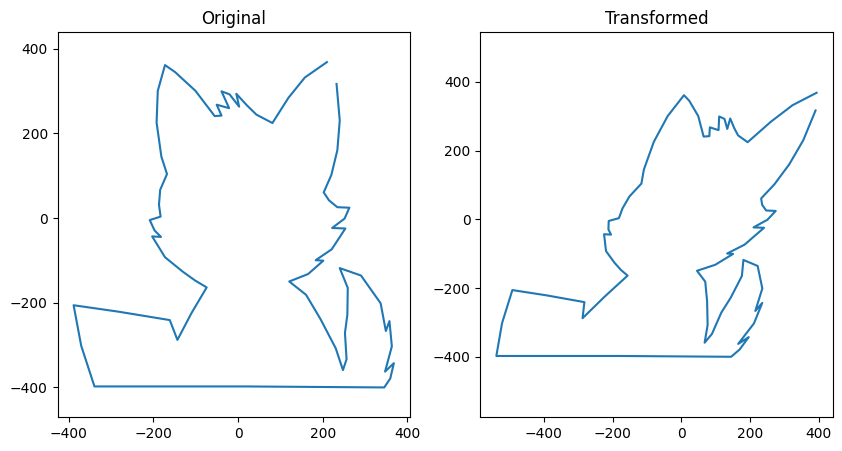

shear 0 0.5
[[1.  0. ]
 [0.5 1. ]]


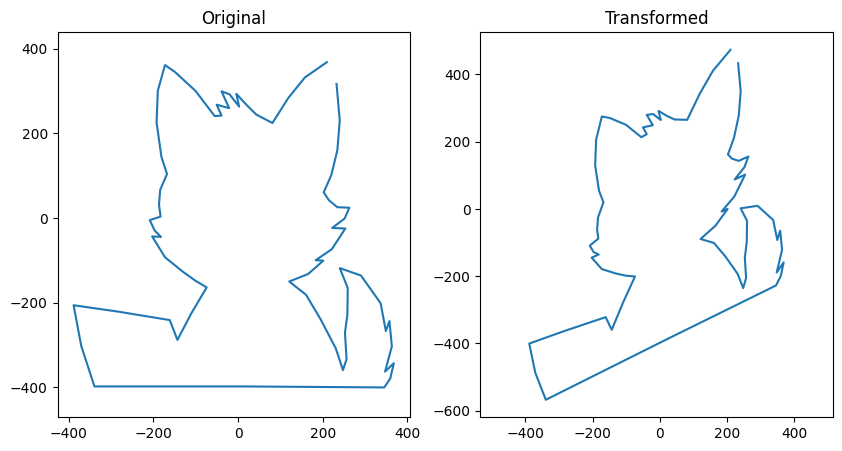

shear 0.5 0.5
[[1.  0.5]
 [0.5 1. ]]


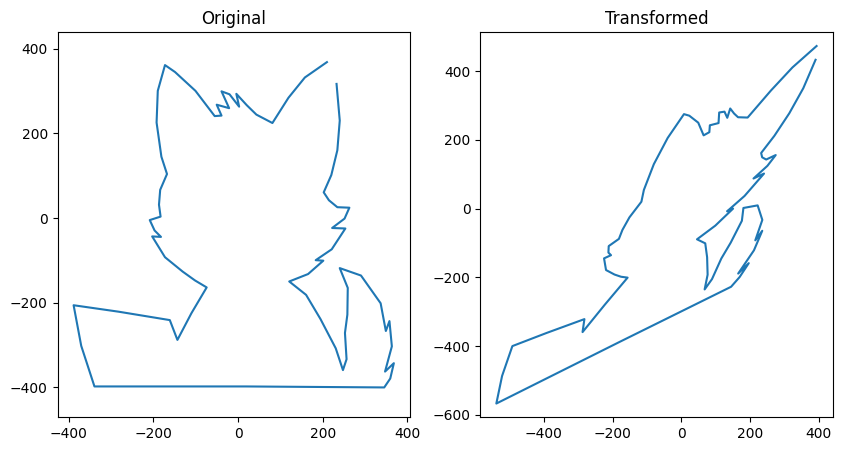

shear -0.5 0
[[ 1.  -0.5]
 [ 0.   1. ]]


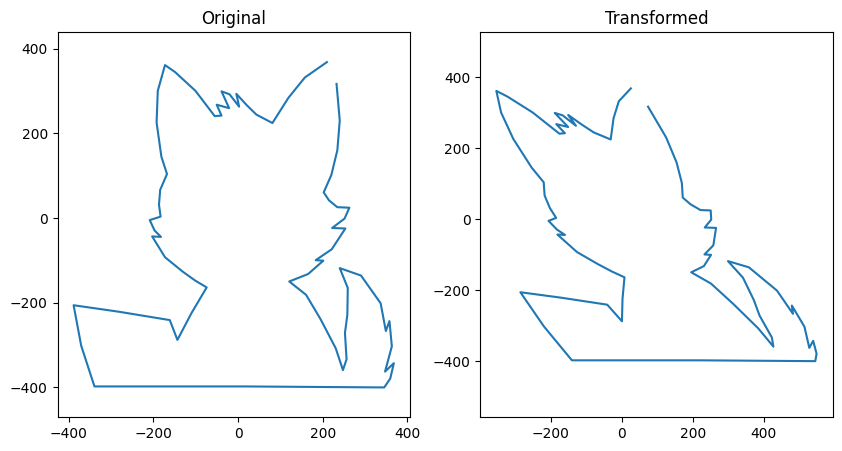

In [ ]:
for a, b in [(0.5, 0), (0, 0.5), (0.5, 0.5), (-0.5, 0)]:
    print("shear", a, b)
    L_new, M = shear(L, a, b)
    show(L, L_new, M)

reflection 1 0
[[ 1.  0.]
 [ 0. -1.]]


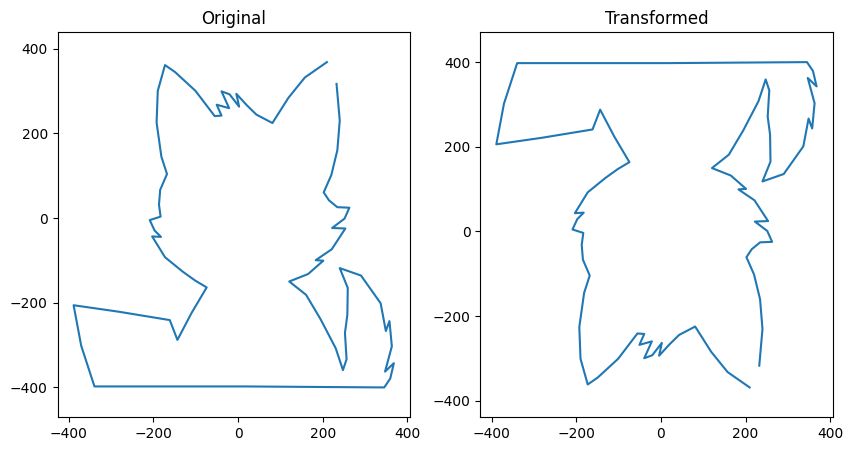

reflection 0 1
[[-1.  0.]
 [ 0.  1.]]


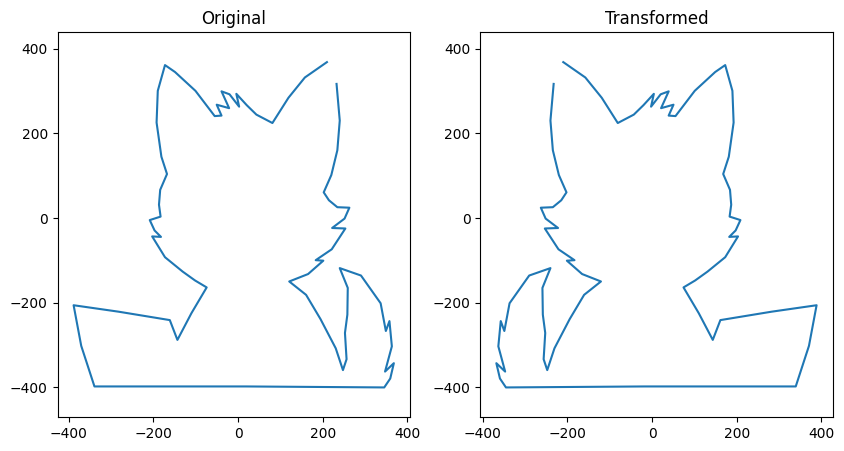

reflection 1 1
[[0. 1.]
 [1. 0.]]


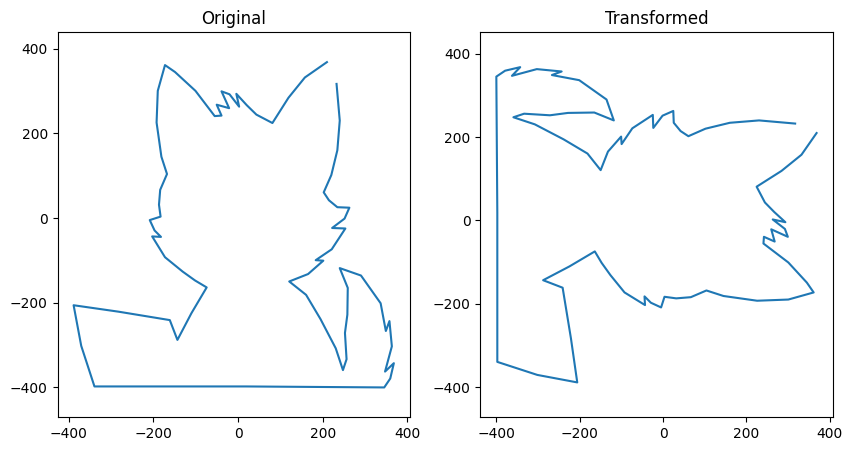

reflection 1 -1
[[ 0. -1.]
 [-1.  0.]]


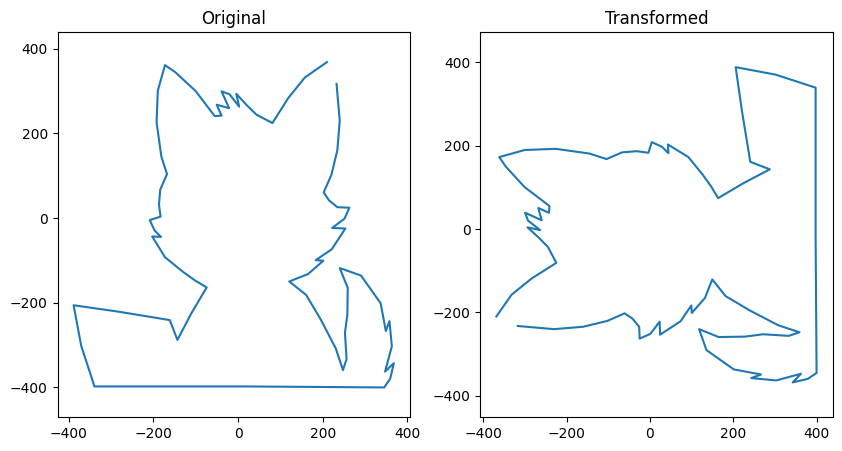

In [ ]:
for a, b in [(1, 0), (0, 1), (1, 1), (1, -1)]:
    print("reflection", a, b)
    L_new, M = reflection(L, a, b)
    show(L, L_new, M)

rotation 1.5707963267948966
[[ 6.123234e-17 -1.000000e+00]
 [ 1.000000e+00  6.123234e-17]]


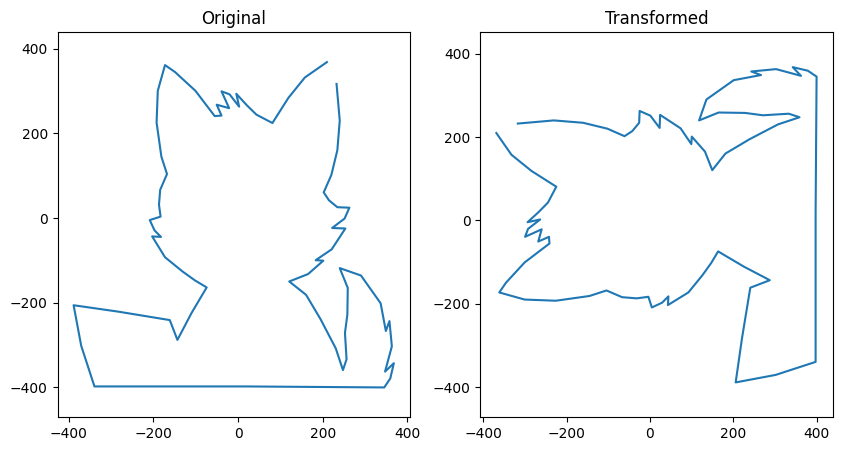

rotation 3.141592653589793
[[-1.0000000e+00 -1.2246468e-16]
 [ 1.2246468e-16 -1.0000000e+00]]


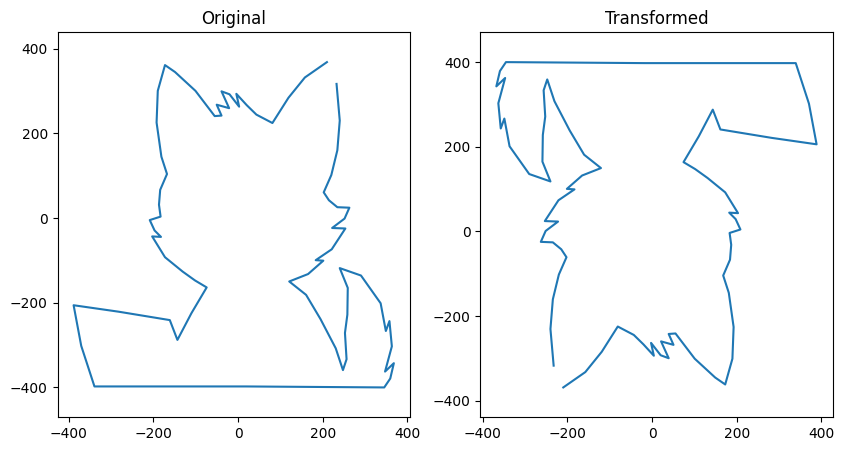

rotation -0.7853981633974483
[[ 0.70710678  0.70710678]
 [-0.70710678  0.70710678]]


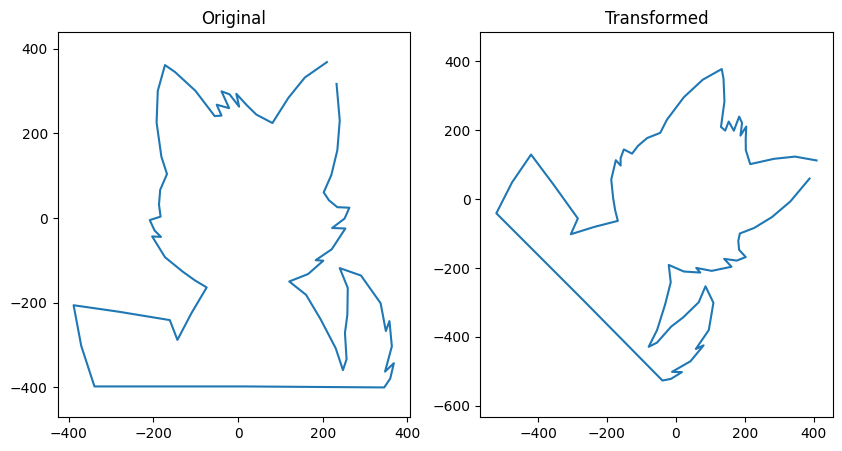

In [ ]:
for angle in [np.pi/2, np.pi, -np.pi/4]:
    print("rotation", angle)
    L_new, M = rotation(L, angle)
    show(L, L_new, M)

### Task 2

stretch, shear, rotation
[[ 1.06066017 -0.24748737]
 [ 1.06066017  0.74246212]]


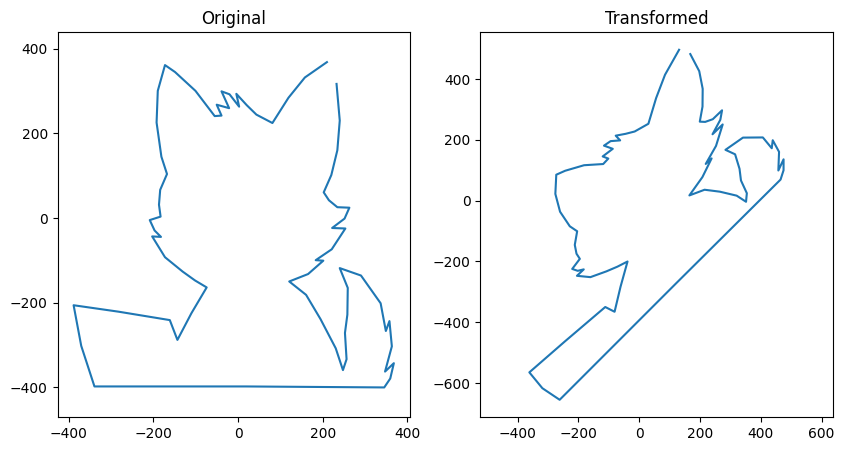

shear, stretch, rotation
[[1.06066017 0.03535534]
 [1.06066017 1.02530483]]


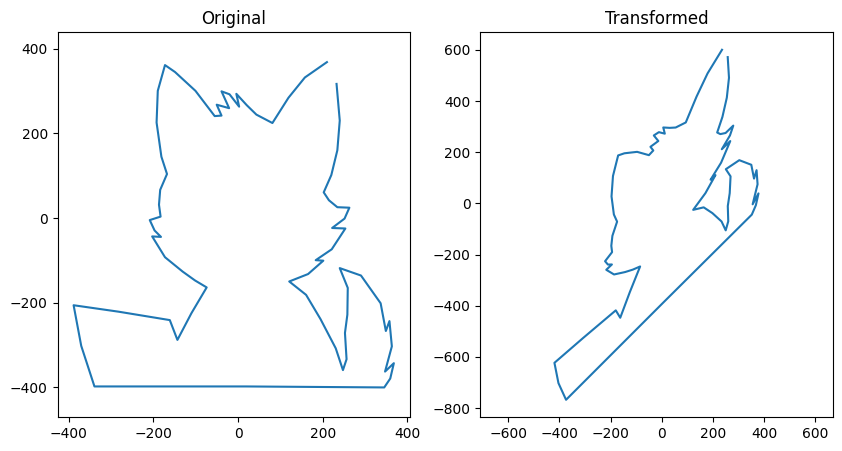

rotation, shear, stretch
[[ 1.59099026 -0.53033009]
 [ 0.49497475  0.49497475]]


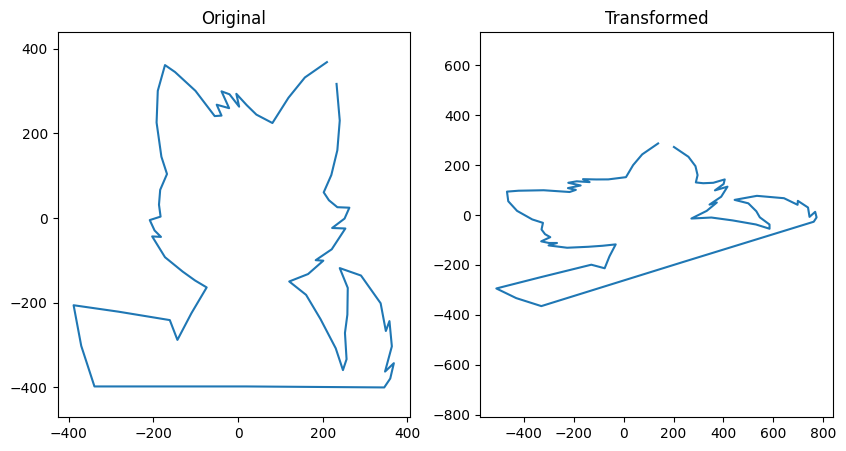

In [ ]:
image = lynx.T

P1, M1 = stretch(image, 1.5, 0.7)
P2, M2 = shear(P1, 0.5, 0)
P3, M3 = rotation(P2, np.pi/4)

M_total = M3 @ M2 @ M1
print("stretch, shear, rotation")
show(image, P3, M_total)

P1, M1 = shear(image, 0.5, 0)
P2, M2 = stretch(P1, 1.5, 0.7)
P3, M3 = rotation(P2, np.pi/4)

M_total = M3 @ M2 @ M1
print("shear, stretch, rotation")
show(image, P3, M_total)

P1, M1 = rotation(image, np.pi/4)
P2, M2 = shear(P1, 0.5, 0)
P3, M3 = stretch(P2, 1.5, 0.7)

M_total = M3 @ M2 @ M1
print("rotation, shear, stretch")
show(image, P3, M_total)

При різному порядку дій у нас виходить різний результат, оскільки множення матрицб не комутативне, а отже при перестановці ми отримаємо різні матриці перетворень, і відповідно різні результати

## Part 2

###Task 3

In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip install -q -U kaggle
!kaggle datasets download -d balraj98/modelnet40-princeton-3d-object-dataset
!unzip -l modelnet40-princeton-3d-object-dataset.zip | grep airplane | head

Dataset URL: https://www.kaggle.com/datasets/balraj98/modelnet40-princeton-3d-object-dataset
License(s): other
modelnet40-princeton-3d-object-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
   533494  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0627.off
  7651954  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0628.off
   516436  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0629.off
  1705849  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0630.off
   609059  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0631.off
   696244  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0632.off
  2231892  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0633.off
  1966428  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0634.off
  1195911  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0635.off
  2331168  2020-10-28 11:40   ModelNet40/airplane/test/airplane_0636.off


replace airplanes/ModelNet40/airplane/test/airplane_0627.off? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
(11634, 3)


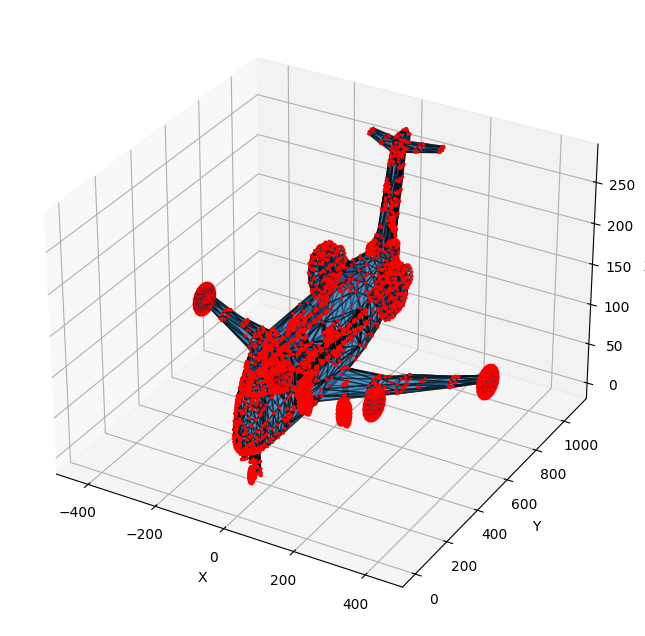

In [ ]:
!unzip -q modelnet40-princeton-3d-object-dataset.zip "ModelNet40/airplane/test/airplane_0627.off" -d airplanes

vertices, faces = read_off("airplanes/ModelNet40/airplane/test/airplane_0627.off")
print(vertices.shape)
plot_off(vertices, faces)

In [ ]:
def rotate_xy(X, angle):
    X = X.copy()
    M = np.array([[np.cos(angle), -np.sin(angle), 0], [np.sin(angle),  np.cos(angle), 0], [0, 0, 1]])
    return M @ X, M

In [ ]:
def rotate_yz(X, angle):
    X = X.copy()
    M = np.array([[1, 0, 0], [0,  np.cos(angle), -np.sin(angle)], [0, np.sin(angle), np.cos(angle)]])
    return M @ X, M

In [ ]:
def rotate_xz(X, angle):
    X = X.copy()
    M = np.array([[np.cos(angle), 0, -np.sin(angle)], [0, 1, 0], [np.sin(angle), 0, np.cos(angle)]])
    return M @ X, M

[[ 0.70710678 -0.70710678  0.        ]
 [ 0.70710678  0.70710678  0.        ]
 [ 0.          0.          1.        ]]


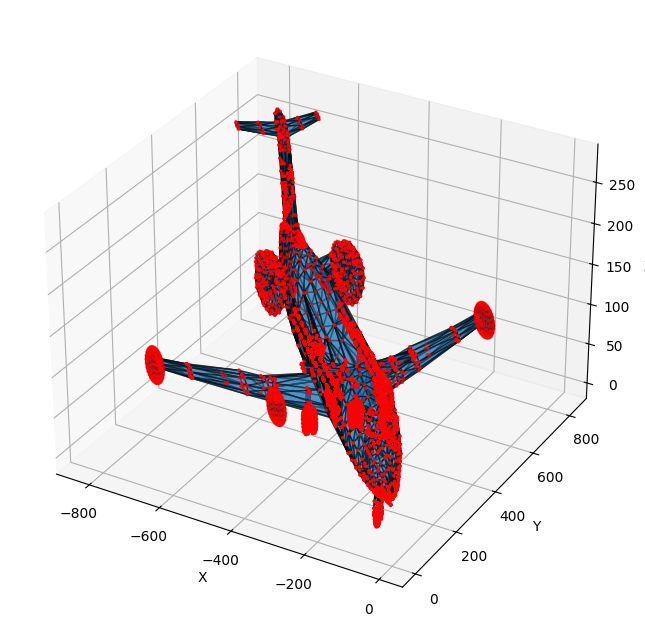

[[ 1.          0.          0.        ]
 [ 0.          0.70710678 -0.70710678]
 [ 0.          0.70710678  0.70710678]]


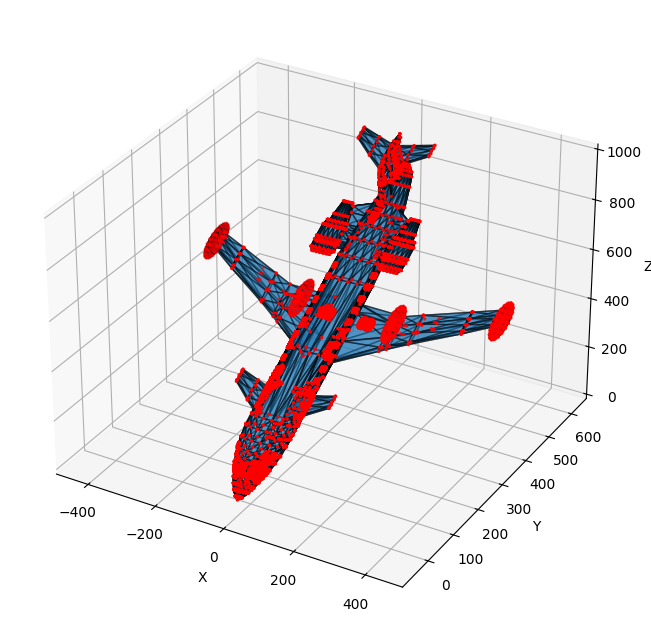

[[ 0.70710678  0.         -0.70710678]
 [ 0.          1.          0.        ]
 [ 0.70710678  0.          0.70710678]]


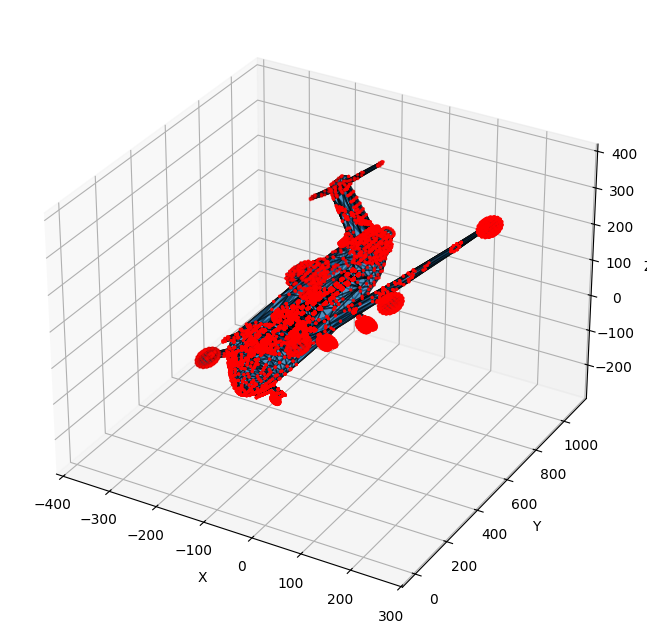

In [ ]:
X = vertices.T

X_xy, M = rotate_xy(X, np.pi/4)
vertices_xy = X_xy.T
print(M)
plot_off(vertices_xy, faces)

X_yz, M = rotate_yz(X, np.pi/4)
vertices_yz = X_yz.T
print(M)
plot_off(vertices_yz, faces)

X_xz, M = rotate_xz(X, np.pi/4)
vertices_xz = X_xz.T
print(M)
plot_off(vertices_xz, faces)

###Task 4

[[ 0.12682648 -0.78033009 -0.61237244]
 [ 0.35355339  0.61237244 -0.70710678]
 [ 0.9267767  -0.12682648  0.35355339]]


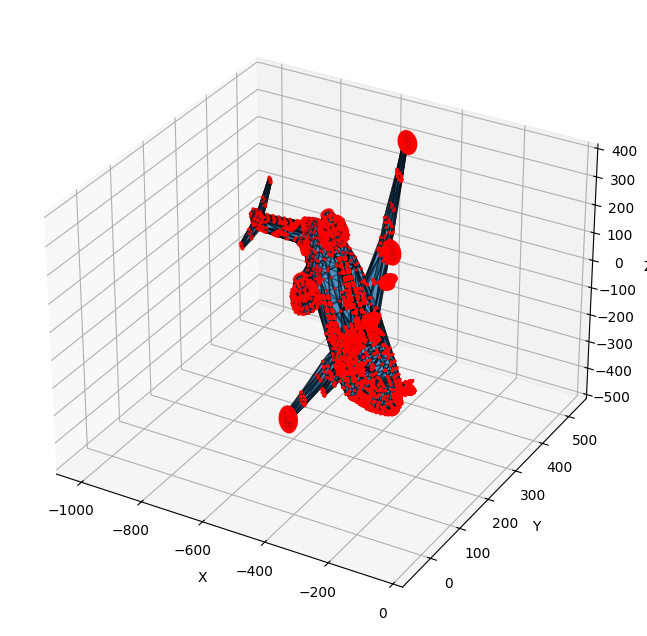

In [ ]:
X1, M1 = rotate_xy(X, np.pi/6)
X2, M2 = rotate_yz(X1, np.pi/4)
X3, M3 = rotate_xz(X2, np.pi/3)

M_total = M3 @ M2 @ M1
print(M_total)
plot_off(X3.T, faces)